In [1]:
import pandas as pd 
import seaborn as sns
import numpy as np
import matplotlib.pyplot as plt

import warnings
warnings.filterwarnings("ignore")

# 1. ***Eploratory Data Analysis***

In [2]:
data = pd.read_csv('global_cancer_patients_2015_2024 (1).csv')

In [3]:
data.head(5)

,Patient_ID,Age,Gender,Country_Region,Year,Genetic_Risk,Air_Pollution,Alcohol_Use,Smoking,Obesity_Level,Cancer_Type,Cancer_Stage,Treatment_Cost_USD,Survival_Years,Target_Severity_Score
0,PT0000000,71,Male,UK,2021,6.4,2.8,9.5,0.9,8.7,Lung,Stage III,62913.44,5.9,4.92
1,PT0000001,34,Male,China,2021,1.3,4.5,3.7,3.9,6.3,Leukemia,Stage 0,12573.41,4.7,4.65
2,PT0000002,80,Male,Pakistan,2023,7.4,7.9,2.4,4.7,0.1,Breast,Stage II,6984.33,7.1,5.84
3,PT0000003,40,Male,UK,2015,1.7,2.9,4.8,3.5,2.7,Colon,Stage I,67446.25,1.6,3.12
4,PT0000004,43,Female,Brazil,2017,5.1,2.8,2.3,6.7,0.5,Skin,Stage III,77977.12,2.9,3.62


In [4]:
data.info()

<class 'pandas.DataFrame'>
RangeIndex: 50000 entries, 0 to 49999
Data columns (total 15 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   Patient_ID             50000 non-null  str    
 1   Age                    50000 non-null  int64  
 2   Gender                 50000 non-null  str    
 3   Country_Region         50000 non-null  str    
 4   Year                   50000 non-null  int64  
 5   Genetic_Risk           50000 non-null  float64
 6   Air_Pollution          50000 non-null  float64
 7   Alcohol_Use            50000 non-null  float64
 8   Smoking                50000 non-null  float64
 9   Obesity_Level          50000 non-null  float64
 10  Cancer_Type            50000 non-null  str    
 11  Cancer_Stage           50000 non-null  str    
 12  Treatment_Cost_USD     50000 non-null  float64
 13  Survival_Years         50000 non-null  float64
 14  Target_Severity_Score  50000 non-null  float64
dtypes: float64(8)

In [5]:
data.duplicated().sum()

np.int64(0)

# Descriptive Analysis

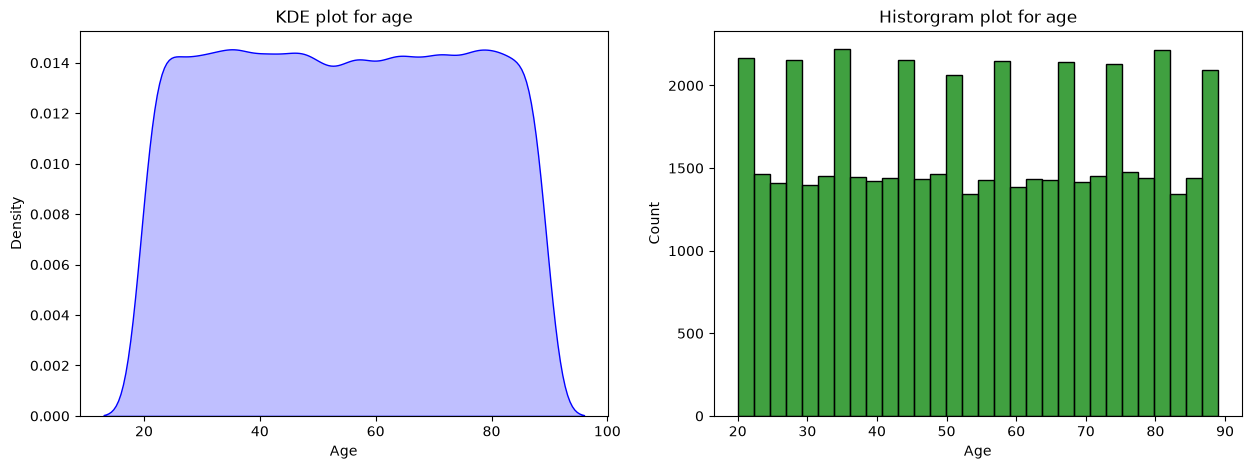

In [6]:
#Plotting for age column

plt.figure(figsize=(15, 5))

plt.subplot(1,2,1)
sns.kdeplot(data=data["Age"],
            fill=True,
            color="blue")
plt.title("KDE plot for age")

plt.subplot(1,2,2)
sns.histplot(data=data["Age"],
            fill=True,
            color="green",
            bins=30)
plt.title("Historgram plot for age")

plt.show()


In [8]:
data['Age'].describe()

count    50000.000000
mean        54.421540
std         20.224451
min         20.000000
25%         37.000000
50%         54.000000
75%         72.000000
max         89.000000
Name: Age, dtype: float64

In [9]:
#Gender Column

data["Gender"].value_counts()

Gender
Male      16796
Female    16709
Other     16495
Name: count, dtype: int64

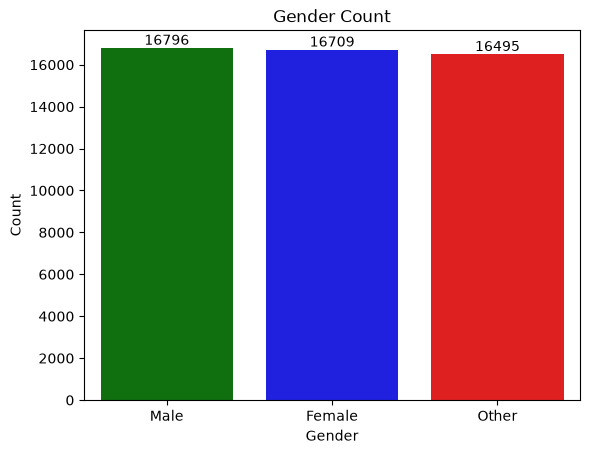

In [10]:
#plotting for Gender Column

sns.barplot(
           x = data["Gender"].value_counts().index,
           y = data["Gender"].value_counts().values,
            palette=['green', 'blue', 'red'])

for i, v in enumerate(data["Gender"].value_counts()):
    plt.text(i, v, str(v),
            ha='center', 
             va='bottom', 
             fontsize=10)

plt.title("Gender Count")
plt.xlabel('Gender')
plt.ylabel('Count')
plt.show()

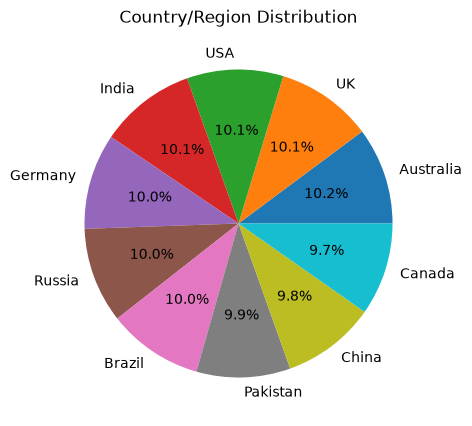

In [11]:
#countries column

country_counts = data["Country_Region"].value_counts()

plt.figure(figsize=(15, 5))

plt.pie(x = country_counts.values,
      labels = country_counts.index,
      autopct='%1.1f%%')

plt.title('Country/Region Distribution')
plt.show()

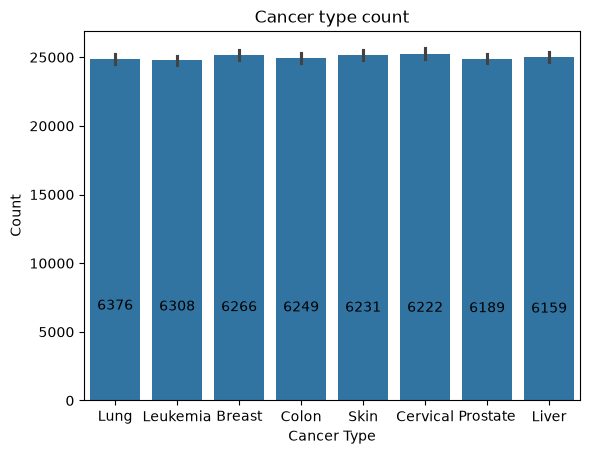

In [12]:
#Cancer type

data["Cancer_Type"].value_counts()

# plt.figure(figsize=(15, 5))
sns.barplot(x = data["Cancer_Type"].values,
            y=data["Cancer_Type"].index)

for i,v in enumerate(data["Cancer_Type"].value_counts()):
    plt.text(i, v, str(v), 
            ha='center',
            va='bottom')

plt.title("Cancer type count")
plt.xlabel("Cancer Type")
plt.ylabel("Count")
plt.show()

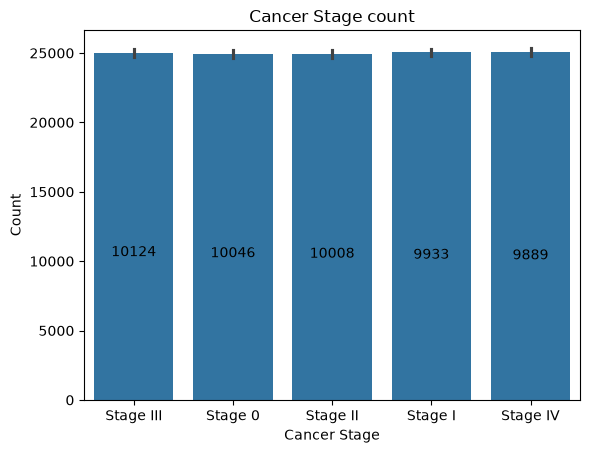

In [13]:
#camcer stage

data["Cancer_Stage"].value_counts()

# plt.figure(figsize=(15, 5))
sns.barplot(x = data["Cancer_Stage"].values,
            y = data["Cancer_Stage"].index)

for i,v in enumerate(data["Cancer_Stage"].value_counts()):
    plt.text(i, v, str(v), 
            ha = 'center',
            va = 'bottom')

plt.title("Cancer Stage count")
plt.xlabel("Cancer Stage")
plt.ylabel("Count")
plt.show()

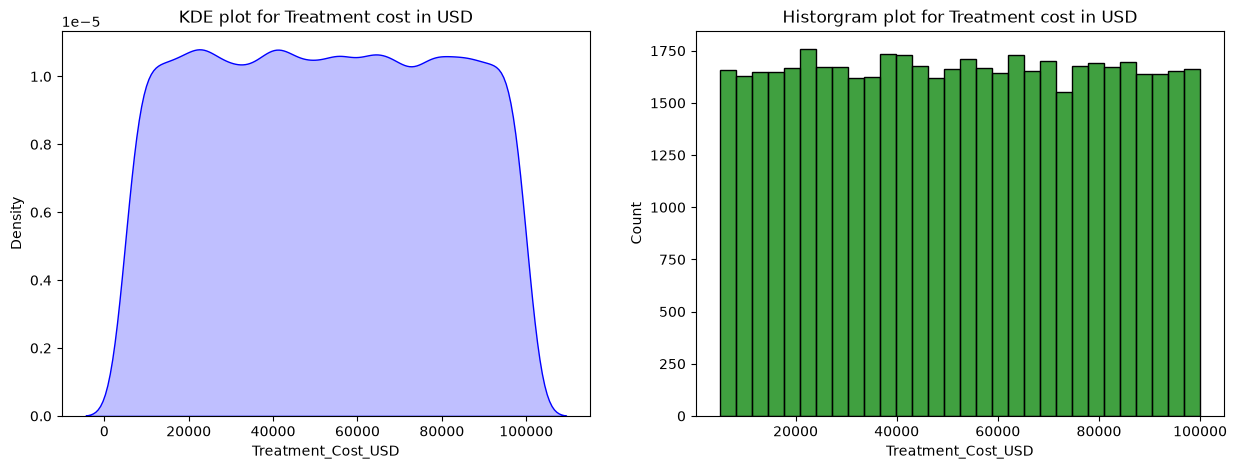

In [14]:
#plotting for treatment cost

plt.figure(figsize=(15, 5))

plt.subplot(1,2,1)
sns.kdeplot(data=data["Treatment_Cost_USD"],
            fill=True,
            color="blue")
plt.title("KDE plot for Treatment cost in USD")

plt.subplot(1,2,2)
sns.histplot(data=data["Treatment_Cost_USD"],
            fill=True,
            color="green",
            bins=30)
plt.title("Historgram plot for Treatment cost in USD")

plt.show()

In [15]:
data["Treatment_Cost_USD"].describe()

count    50000.000000
mean     52467.298239
std      27363.229379
min       5000.050000
25%      28686.225000
50%      52474.310000
75%      76232.720000
max      99999.840000
Name: Treatment_Cost_USD, dtype: float64

In [16]:
#Analizign the risk factor

column_of_intrest = ['Genetic_Risk', 'Air_Pollution', 'Alcohol_Use', 'Smoking', 'Obesity_Level']

summary = data[column_of_intrest].agg(['mean', 'std', 'min', 'max'])

summary

,Genetic_Risk,Air_Pollution,Alcohol_Use,Smoking,Obesity_Level
mean,5.001698,5.010126,5.010880,4.989826,4.991176
std,2.885773,2.888399,2.888769,2.881579,2.894504
min,0.000000,0.000000,0.000000,0.000000,0.000000
max,10.000000,10.000000,10.000000,10.000000,10.000000


# 2. ***Inferential &  Predective Analysis***

### ***2.1 - Determine the relationship between risk factor  and cancer severity***

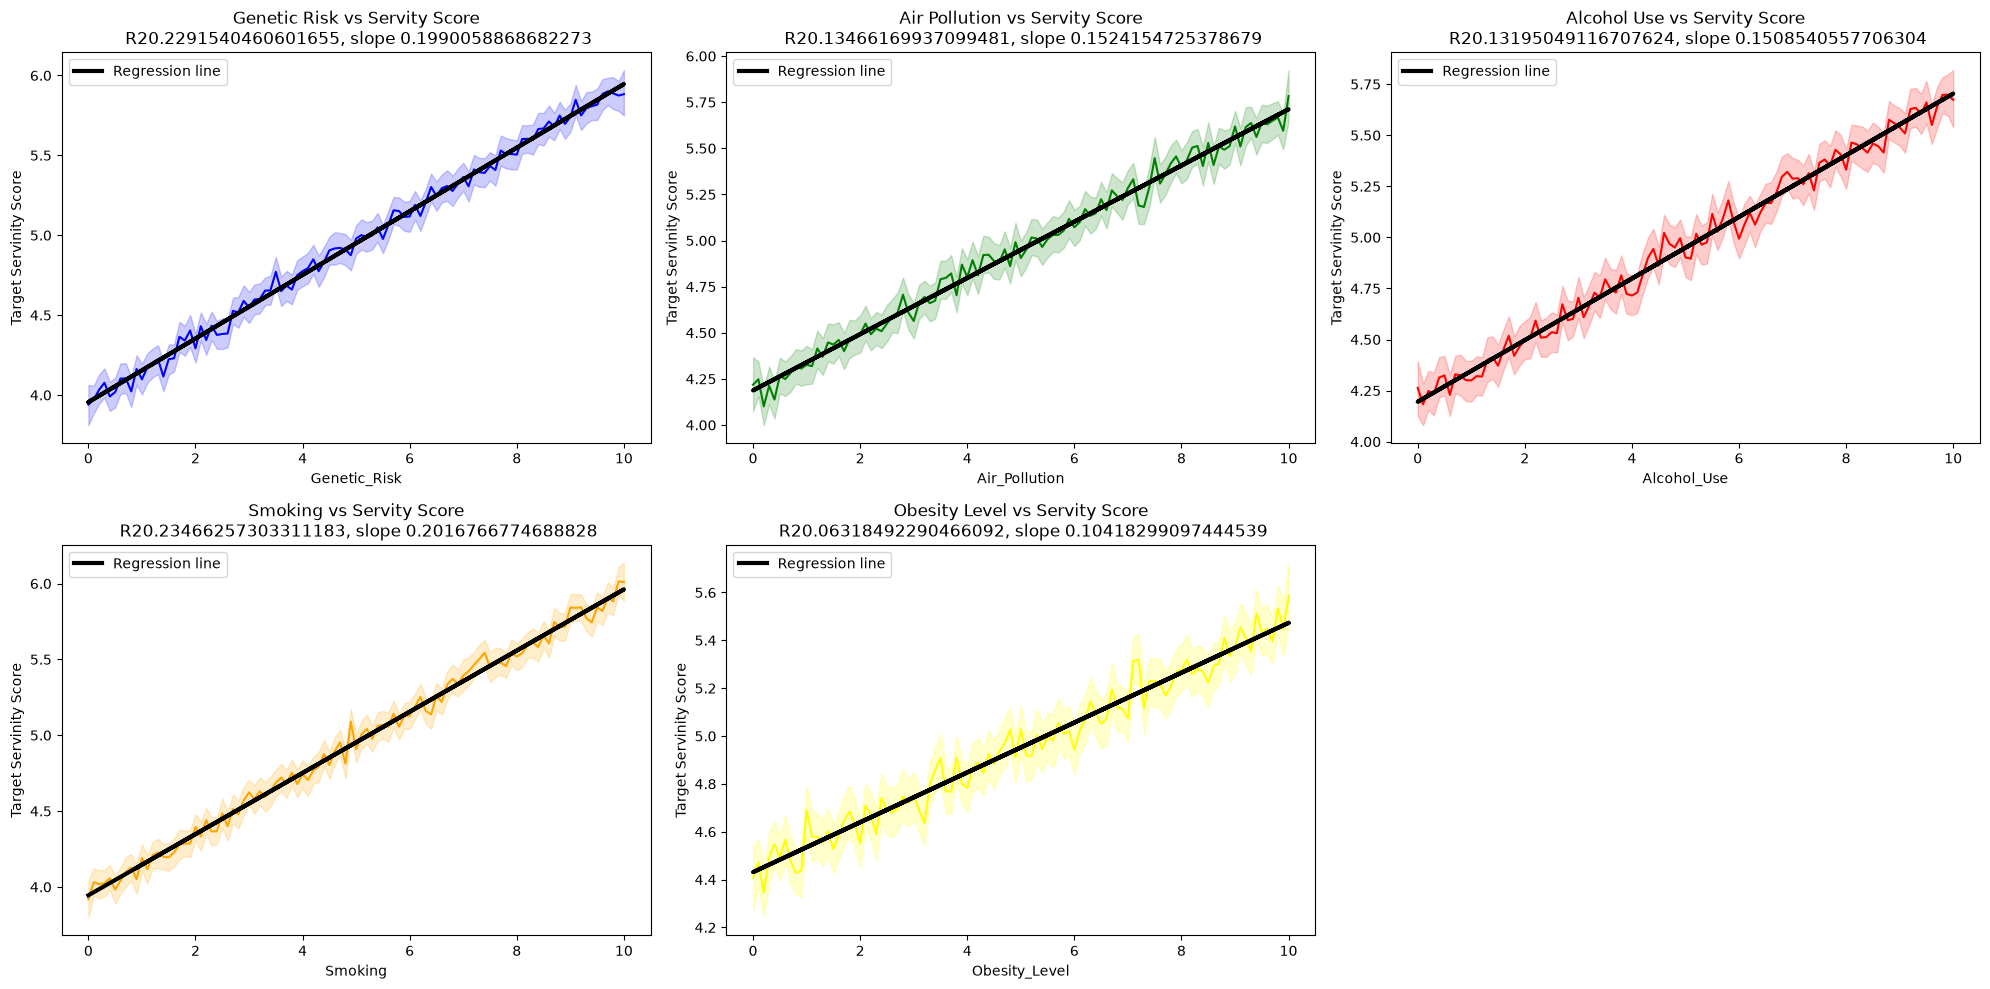

In [47]:
from scipy.stats import linregress

risk_factor = ['Genetic_Risk', 'Air_Pollution', 'Alcohol_Use', 'Smoking', 'Obesity_Level']
titles = ['Genetic Risk', 'Air Pollution', 'Alcohol Use', 'Smoking', 'Obesity Level']
colors = ["blue", "green", "red", "orange", "yellow"]

plt.figure(figsize=(20, 10))
for i, (factor, title, color) in enumerate(zip(risk_factor, titles, colors), start=1):
    plt.subplot(2, 3, i)

    X = data[factor]
    y = data["Target_Severity_Score"]
    slope, intercept, r_value, p_value, std_error = linregress(X, y)

    r_squared = r_value**2
    
    sns.lineplot(x=X, y=y, data=data, color=color)
    plt.plot(X, X*slope+intercept, color="black", linewidth=3, label="Regression line")
    plt.title(f"{title} vs Servity Score\n R2{r_squared}, slope {slope}")
    plt.xlabel(factor)
    plt.ylabel("Target Servinity Score")    
    plt.legend()
    
plt.tight_layout()
plt.show()

### ***2.2 - Analyze the proportion of early-stage diagnoses by cancer type***

In [48]:
stage_count = data[data["Cancer_Type"] == 'Lung']["Cancer_Stage"].value_counts()

early_stage_count = stage_count.get("Stage 0", 0) + stage_count.get("Stage I", 0)
# print(early_stage_count)
total_sum = stage_count.sum()
# print(total_sum)
proportion = (early_stage_count/total_sum)*100
print(f"Proportion of stage cancer dignosis at stage 0 and stage 1 -  {proportion:.2f}")

Proportion of stage cancer dignosis at stage 0 and stage 1 -  38.43


In [49]:
stage_count = data[data["Cancer_Type"] == 'Leukemia']["Cancer_Stage"].value_counts()

early_stage_count = stage_count.get("Stage 0", 0) + stage_count.get("Stage I", 0)
# print(early_stage_count)
total_sum = stage_count.sum()
# print(total_sum)
proportion = (early_stage_count/total_sum)*100
print(f"Proportion of Leukemia dignosis at stage 0 and stage 1 -  {proportion:.2f}")

Proportion of Leukemia dignosis at stage 0 and stage 1 -  39.53


In [50]:
stage_count = data[data["Cancer_Type"] == 'Breast']["Cancer_Stage"].value_counts()

early_stage_count = stage_count.get("Stage 0", 0) + stage_count.get("Stage I", 0)
# print(early_stage_count)
total_sum = stage_count.sum()
# print(total_sum)
proportion = (early_stage_count/total_sum)*100
print(f"Proportion of Breast dignosis at stage 0 and stage 1 -  {proportion:.2f}")

Proportion of Breast dignosis at stage 0 and stage 1 -  39.47


In [51]:
stage_count = data[data["Cancer_Type"] == 'Colon']["Cancer_Stage"].value_counts()

early_stage_count = stage_count.get("Stage 0", 0) + stage_count.get("Stage I", 0)
# print(early_stage_count)
total_sum = stage_count.sum()
# print(total_sum)
proportion = (early_stage_count/total_sum)*100
print(f"Proportion of Colon dignosis at stage 0 and stage 1 -  {proportion:.2f}")

Proportion of Colon dignosis at stage 0 and stage 1 -  40.42


In [52]:
stage_count = data[data["Cancer_Type"] == 'Skin']["Cancer_Stage"].value_counts()

early_stage_count = stage_count.get("Stage 0", 0) + stage_count.get("Stage I", 0)
# print(early_stage_count)
total_sum = stage_count.sum()
# print(total_sum)
proportion = (early_stage_count/total_sum)*100
print(f"Proportion of Skin dignosis at stage 1 and stage 0 -  {proportion:.2f}")

Proportion of Skin dignosis at stage 1 and stage 0 -  40.41


In [53]:
stage_count = data[data["Cancer_Type"] == 'Cervical']["Cancer_Stage"].value_counts()

early_stage_count = stage_count.get("Stage 0", 0) + stage_count.get("Stage I", 0)
# print(early_stage_count)
total_sum = stage_count.sum()
# print(total_sum)
proportion = (early_stage_count/total_sum)*100
print(f"Proportion of Cervical dignosis at stage 0 and stage 1 -  {proportion:.2f}")

Proportion of Cervical dignosis at stage 0 and stage 1 -  39.86


In [54]:
stage_count = data[data["Cancer_Type"] == 'Prostate']["Cancer_Stage"].value_counts()

early_stage_count = stage_count.get("Stage 0", 0) + stage_count.get("Stage I", 0)
# print(early_stage_count)
total_sum = stage_count.sum()
# print(total_sum)
proportion = (early_stage_count/total_sum)*100
print(f"Proportion of  Prostate dignosis at stage 0 and stage 1 -  {proportion:.2f}")

Proportion of  Prostate dignosis at stage 0 and stage 1 -  40.19


In [55]:
stage_count = data[data["Cancer_Type"] == 'Liver']["Cancer_Stage"].value_counts()

early_stage_count = stage_count.get("Stage 0", 0) + stage_count.get("Stage I", 0)
# print(early_stage_count)
total_sum = stage_count.sum()
# print(total_sum)
proportion = (early_stage_count/total_sum)*100
print(f"Proportion of Liver dignosis at stage 0 and stage 1 -  {proportion:.2f}")

Proportion of Liver dignosis at stage 0 and stage 1 -  40.61


### ***2.3 - Identify key predictors of cancer severity and survival years.***

In [56]:
features = ['Age', 'Genetic_Risk', 'Air_Pollution', 'Alcohol_Use', 'Smoking', 'Obesity_Level']
targets   = ['Survival_Years', 'Target_Severity_Score']

#Calculate Correlation
pearson_correlation = data[features+targets].corr(method='pearson')
spearman_correlation = data[features+targets].corr(method='spearman')

#slice out only thee relation with target variable
pearson_result = pearson_correlation[targets]
spearman_result = spearman_correlation[targets]

correlation_df = pd.concat([pearson_result, spearman_result], axis=1, keys=['Pearson', 'Speaerman'])
correlation_df

Pearson                            Speaerman  \
                      Survival_Years Target_Severity_Score Survival_Years   
Age                        -0.000147             -0.001481      -0.000149   
Genetic_Risk                0.001708              0.478700       0.001684   
Air_Pollution               0.000893              0.366963       0.000841   
Alcohol_Use                -0.000527              0.363250      -0.000543   
Smoking                     0.001371              0.484420       0.001372   
Obesity_Level               0.009771              0.251366       0.009780   
Survival_Years              1.000000              0.004161       1.000000   
Target_Severity_Score       0.004161              1.000000       0.003431   

                                             
                      Target_Severity_Score  
Age                               -0.002076  
Genetic_Risk                       0.472193  
Air_Pollution                      0.357528  
Alcohol_Use                        0.354694  
Smoking                            0.477881  
Obesity_Level                      0.243152  
Survival_Years                     0.003431  
Target_Severity_Score              1.000000

## Correlation with Target Severity Score

| Feature | Pearson | Spearman | Interpretation |
|---|---|---|---|
| **Smoking** | 0.484 | 0.478 | Strong positive correlation. Higher smoking levels are associated with higher severity scores. |
| **Genetic_Risk** | 0.479 | 0.472 | Strong positive correlation. Genetic predisposition is a significant factor in severity. |
| **Air_Pollution** | 0.367 | 0.358 | Moderate positive correlation. Suggests environmental exposure contributes to severity. |
| **Alcohol_Use** | 0.363 | 0.355 | Moderate positive correlation. Alcohol consumption may play a role in worsening severity. |
| **Obesity_Level** | 0.251 | 0.243 | Weak to moderate positive correlation. There is some association between obesity and severity. |
| **Treatment_Cost** | -0.466 | -0.459 | Strong negative correlation. Higher severity cases tend to have lower treatment costs, which may reflect healthcare access issues or late-stage diagnosis limiting treatment. |

## Correlation with Target Survival Duration

| Feature | Pearson | Spearman | Interpretation |
|---|---|---|---|
| **All Features** | ~0.000 | ~0.000 | Negligible or no correlation. These variables do not show any significant linear or monotonic association with survival duration. |

In [57]:
#Random forest for target severity score.
from sklearn.ensemble import RandomForestRegressor
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder
from sklearn.metrics import *

#Converting Categorical colm to numerical column
categorical_col = ["Gender", "Country_Region", "Cancer_Type", "Cancer_Stage"]

for col in categorical_col:
    le = LabelEncoder()
    data[col] = le.fit_transform(data[col])

#Prepareing features and input
X = data.drop(columns=['Patient_ID', 'Treatment_Cost_USD', 'Survival_Years', 'Target_Severity_Score'])
y_serivity = data["Target_Severity_Score"]

#train test split
X_train_s, X_test_s, y_train_s, y_test_s = train_test_split(X, y_serivity,
                                                   test_size=0.2,
                                                   random_state=42)

# train the model
model = RandomForestRegressor(n_estimators=200, 
                     max_depth=None, 
                     min_samples_split=2, 
                     min_samples_leaf=1, 
                     random_state=42)

model.fit(X_train_s, y_train_s)

#evaluate the model

train_r2_severity = r2_score(y_train_s, model.predict(X_train_s))
test_r2_severity  = r2_score(y_test_s,model.predict(X_test_s))

In [58]:
print(train_r2_severity)
print(test_r2_severity)

0.9689874030069515
0.7681690458480587


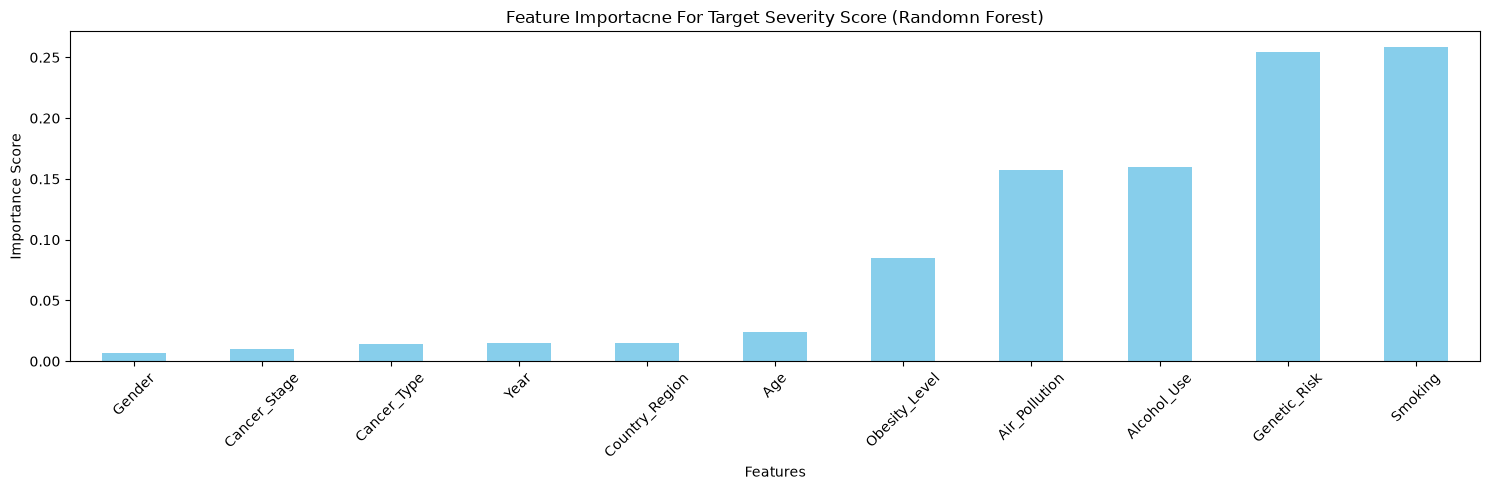

In [59]:
feature_importance_severity = pd.Series(model.feature_importances_, index=X.columns).sort_values(ascending=True)

#plotting feature importanceabs
plt.figure(figsize=(15, 5))
feature_importance_severity.plot(kind="bar", 
                                color="skyblue")
plt.title("Feature Importacne For Target Severity Score (Randomn Forest)")
plt.xlabel("Features")
plt.ylabel("Importance Score")
plt.xticks(rotation= 45)
plt.tight_layout()
plt.show()

In [61]:
#Random forest for target severity score.
from sklearn.ensemble import RandomForestRegressor
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.preprocessing import LabelEncoder
from sklearn.metrics import *

#Converting Categorical colm to numerical column
categorical_col = ["Gender", "Country_Region", "Cancer_Type", "Cancer_Stage"]

for col in categorical_col:
    le = LabelEncoder()
    data[col] = le.fit_transform(data[col])

#Prepareing features and input
X = data.drop(columns=['Patient_ID', 'Treatment_Cost_USD', 'Survival_Years', 'Target_Severity_Score'])
y_serivity = data["Survival_Years"]

#train test split
X_train_s, X_test_s, y_train_s, y_test_s = train_test_split(X, y_serivity,
                                                   test_size=0.2,
                                                   random_state=42)

param_grid = {
            'n_estimators': [100,200],
            'max_depth': [5,10, None],
            'min_samples_split': [2, 5],
            'min_samples_leaf': [1, 2]
             }

# train the model
model = RandomForestRegressor(random_state=42)

#Grid seaerch CV
GSCV = GridSearchCV(model, 
                    param_grid, cv=3, 
                    scoring="r2", 
                    n_jobs=-1)

GSCV.fit(X_train_s, y_train_s)

best_rf_severity = GSCV.best_estimator_

#evaluate the model
train_r2_severity = r2_score(y_train_s, best_rf_severity.predict(X_train_s))
test_r2_severity  = r2_score(y_test_s,best_rf_severity.predict(X_test_s))

In [62]:
print(train_r2_severity)
print(test_r2_severity)

0.008649540168433778
-0.0001267824928190553


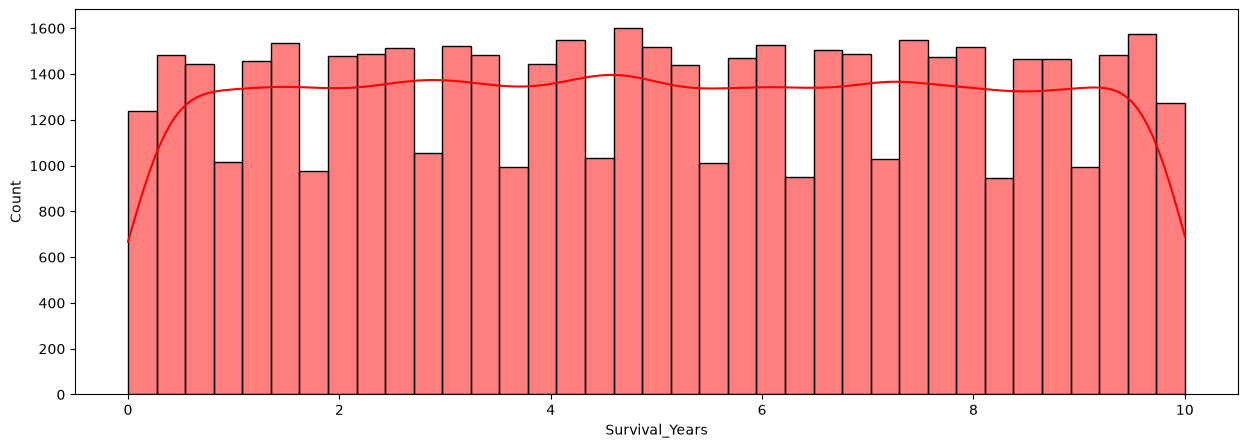

In [70]:
#Plotting his plot

import seaborn as sns
plt.figure(figsize=(15, 5))
sns.histplot(data["Survival_Years"], 
             kde=True, 
             color='red')
plt.show()

In [71]:
data.corr(numeric_only=True)["Survival_Years"].sort_values(ascending=True)

Gender                  -0.007121
Cancer_Stage            -0.003014
Cancer_Type             -0.001717
Alcohol_Use             -0.000527
Treatment_Cost_USD      -0.000429
Age                     -0.000147
Year                     0.000018
Air_Pollution            0.000893
Smoking                  0.001371
Genetic_Risk             0.001708
Target_Severity_Score    0.004161
Country_Region           0.005121
Obesity_Level            0.009771
Survival_Years           1.000000
Name: Survival_Years, dtype: float64

The Information in your column does not help the model to figure out  how long a person will survive 

### ***2.4 - Explore the economic burden of cancer treatment across different demographics and countries***

In [17]:
data = pd.read_csv('global_cancer_patients_2015_2024 (1).csv')
data

,Patient_ID,Age,Gender,Country_Region,Year,Genetic_Risk,Air_Pollution,Alcohol_Use,Smoking,Obesity_Level,Cancer_Type,Cancer_Stage,Treatment_Cost_USD,Survival_Years,Target_Severity_Score
0,PT0000000,71,Male,UK,2021,6.4,2.8,9.5,0.9,8.7,Lung,Stage III,62913.44,5.9,4.92
1,PT0000001,34,Male,China,2021,1.3,4.5,3.7,3.9,6.3,Leukemia,Stage 0,12573.41,4.7,4.65
2,PT0000002,80,Male,Pakistan,2023,7.4,7.9,2.4,4.7,0.1,Breast,Stage II,6984.33,7.1,5.84
3,PT0000003,40,Male,UK,2015,1.7,2.9,4.8,3.5,2.7,Colon,Stage I,67446.25,1.6,3.12
4,PT0000004,43,Female,Brazil,2017,5.1,2.8,2.3,6.7,0.5,Skin,Stage III,77977.12,2.9,3.62
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
49995,PT0049995,80,Male,Pakistan,2023,2.3,7.5,2.8,3.8,2.9,Leukemia,Stage 0,71463.70,1.0,3.63
49996,PT0049996,40,Female,USA,2018,6.4,3.5,2.9,9.0,9.8,Colon,Stage I,49619.66,0.4,6.03
49997,PT0049997,74,Male,Pakistan,2015,6.2,1.6,8.7,4.7,4.0,Breast,Stage 0,5338.25,2.7,6.02
49998,PT0049998,21,Male,Brazil,2018,4.0,6.5,7.6,8.6,8.1,Liver,Stage IV,45100.47,7.5,6.54


In [79]:
# country_gender_cost = data.groupby(["Country_Region", "Gender"])["Treatment_Cost_USD"].mean().reset_index()

In [18]:
data["Age_Group"] = pd.cut(data["Age"],
                         bins=[0, 30, 45, 60, 75, 100],
                         labels=["0-30", "31-45", "45-60", "61-75", "76+"])

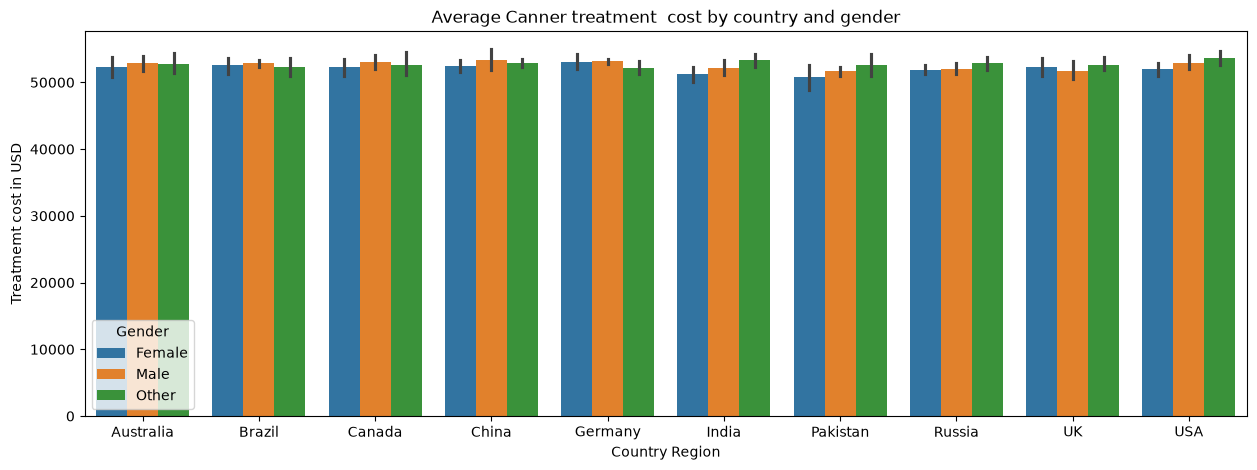

In [35]:
country_age_cost = data.groupby(["Country_Region", "Age_Group", "Gender"])["Treatment_Cost_USD"].mean().reset_index()

#plotting graph

plt.figure(figsize=(15, 5))
sns.barplot(data=country_age_cost,
           x="Country_Region",
           y="Treatment_Cost_USD",
           hue="Gender")

plt.title("Average Cancer treatment  cost by country and gender")
plt.xlabel("Country Region")
plt.ylabel("Treatmemt cost in USD")
plt.show()

In [36]:
country_age_cost = data.groupby(["Country_Region", "Age_Group"])["Treatment_Cost_USD"].mean().reset_index()

In [42]:
#HeatMap Data

heat_map_data = country_age_cost.pivot(index="Age_Group", 
                      columns="Country_Region", 
                      values="Treatment_Cost_USD")

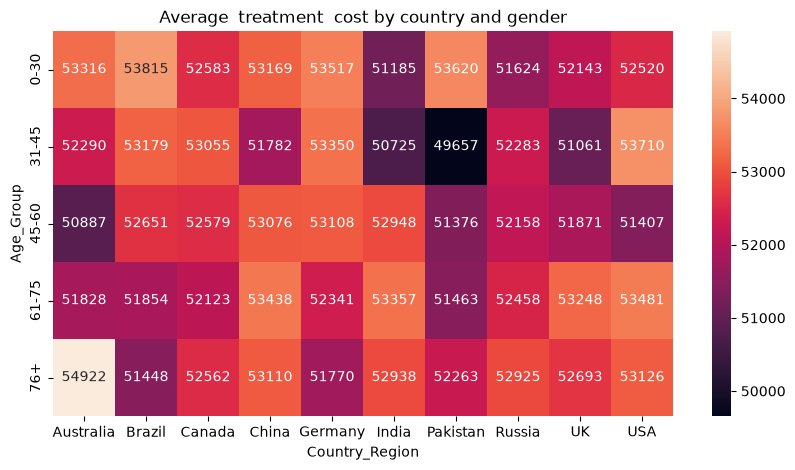

In [46]:
plt.figure(figsize=(10, 5))
sns.heatmap(heat_map_data, 
           annot=True,
           fmt=".0f")

plt.title("Average  treatment  cost by country and gender")
plt.show()

### ***2.5 - Assess whether higher treatment cost is associated with longer survival***

In [63]:
#Importing Libraries

from scipy.stats import pearsonr, spearmanr 
x = data["Treatment_Cost_USD"]
y = data["Survival_Years"]

#peforming pearson correlation_test
pearson_corr, pearson_P_value = pearsonr(x, y)

print(f"Pearson Correlation Coefficient: {pearson_corr}")
print(f"Pearson P-Value : {pearson_P_value}\n")

#peforming pearson correlation_test
spearman_corr, spearman_P_value = spearmanr(x, y)

print(f"Pearson Correlation Coefficient: {spearman_corr}")
print(f"Pearson P-Value : {spearman_P_value}\n")

#Significance value

alpha =  0.5

def interpret_corr(corr, p_value, method):
    if p_value < alpha:
        print(f"{method}, We reject the null hupothesis")
    else:
        print(f"{method}, we Accept null hypothesis/failed to reject null hypothesis")

interpret_corr(pearson_corr, pearson_P_value, "Pearsonr")

interpret_corr(spearman_corr, spearman_P_value, "Spearman")

Pearson Correlation Coefficient: -0.0004294054283021484
Pearson P-Value : 0.9235082012963309

Pearson Correlation Coefficient: -0.0004454737292549569
Pearson P-Value : 0.9206551702014917

Pearsonr, we Accept null hypothesis/failed to reject null hypothesis
Spearman, we Accept null hypothesis/failed to reject null hypothesis


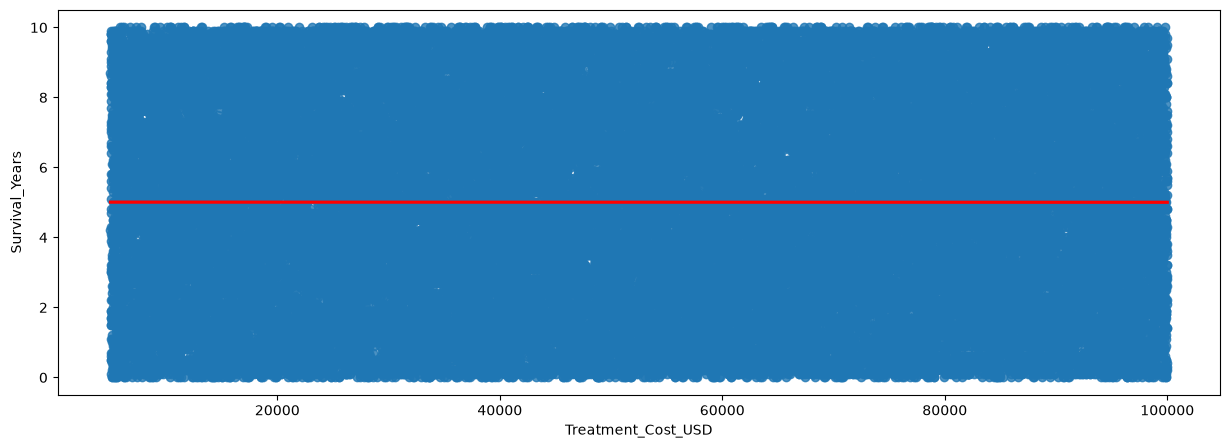

In [65]:

plt.figure(figsize=(15, 5))
sns.regplot(x = x, y = y,
            line_kws=
            {"color" : "red"})
plt.show()

### ***2.6 - Evaluate if higher cancer stages lead to greater treatment costs and reduced survival vears***

In [5]:
df = data.copy() #Copy original data

In [6]:
stages_order =  ['Stage 0', 'Stage I', 'Stage II', 'Stage III', 'Stage IV']

In [7]:
group_stats = df.groupby("Cancer_Stage")[["Treatment_Cost_USD", "Survival_Years"]].mean().reset_index()

In [8]:
group_stats

,Cancer_Stage,Treatment_Cost_USD,Survival_Years
0,Stage 0,52572.589493,5.015199
1,Stage I,52674.079638,5.012990
2,Stage II,52082.841258,4.995170
3,Stage III,52708.197506,5.036311
4,Stage IV,52302.471041,4.972596


In [9]:
grouped_cost = []
grouped_survival = []

for stage in stages_order:
    stage_data = df[df["Cancer_Stage"]==stage]
    cost = stage_data["Treatment_Cost_USD"]
    survival = stage_data["Survival_Years"]

    grouped_cost.append(cost)
    grouped_survival.append(survival)                   

In [10]:
len(grouped_cost)

5

In [11]:
#Check for normality

from scipy.stats import shapiro, f_oneway

normal_cost = 0
normal_survival = 0

for i in  range (len(stages_order)):
    cost_p = shapiro(grouped_cost[i]).pvalue
    surv_p = shapiro(grouped_survival[i]).pvalue

    print(f"cost {cost_p} for group {i}")
    print(f"survival {surv_p} for group {i}")

    if cost_p < 0.5:
        normal_cost+=1

    if surv_p < 0.5:
        normal_survival+=1

cost 1.5471834929640332e-47 for group 0
survival 1.6291054179589865e-47 for group 0
cost 7.306530551009064e-48 for group 1
survival 7.575557907293097e-48 for group 1
cost 8.943587880477399e-48 for group 2
survival 4.041663138012407e-48 for group 2
cost 5.2672747384266664e-48 for group 3
survival 1.3648532948142082e-47 for group 3
cost 1.5838654471109926e-47 for group 4
survival 2.299261925747061e-47 for group 4


In [12]:
print(normal_cost)
print(normal_survival)

5
5


In [17]:
from scipy.stats import kruskal

kruskal_cost = kruskal(*grouped_cost)
kruskal_survival = kruskal(*grouped_survival)

p_Cost = kruskal_cost.pvalue
p_survival = kruskal_survival.pvalue

print(p_Cost)
print(p_survival)

0.4254451689062656
0.6033078729984223


### ***2.7 - Examine whether higher genetic risk amplifies the negative effects of smoking on cancer severity.***

In [32]:
from statsmodels.formula.api import ols

model = ols(
    "Target_Severity_Score ~ Genetic_Risk * Smoking",
    data=data
).fit()

interaction = model.summary2().tables[1].loc["Genetic_Risk:Smoking"]
print(interaction)

Coef.      -0.000228
Std.Err.    0.000471
t          -0.484187
P>|t|       0.628255
[0.025     -0.001150
0.975]      0.000694
Name: Genetic_Risk:Smoking, dtype: float64


In [20]:
data.columns

Index(['Patient_ID', 'Age', 'Gender', 'Country_Region', 'Year', 'Genetic_Risk',
       'Air_Pollution', 'Alcohol_Use', 'Smoking', 'Obesity_Level',
       'Cancer_Type', 'Cancer_Stage', 'Treatment_Cost_USD', 'Survival_Years',
       'Target_Severity_Score'],
      dtype='str')

In [ ]:
p_value = 0.628255